In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import scipy.optimize as sol
import scipy.integrate as integrate
from scipy.stats import uniform
from scipy.stats import norm
import warnings
import random

In [28]:
class cell:
    def __init__(self,index,init_clusters,parent,birth,tau):
        '''Initializes cell attributes
        param:: index: cell index
        param:: clusters: count of n-clusters
        param:: x: plasmid trajectory in time 
        param:: t: time stamps for x
        param:: parent: parent cell
        param:: birth: birth time
        return:: None
        '''
        self.index=index
        self.init_clusters=init_clusters
        self.fin_clusters=[]
        self.x = []
        self.t = []
        self.parent = parent
        self.birth = birth
        self.div = birth+tau#+np.random.normal(0,1)

#@jit
def find_tot_plasmids(y1,y2,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y2[0]+=y2[1]
    y1[1]=y1[0]
    y2[1]=y2[0]
    y_tot1 = np.dot(np.arange(1,max_size),y1[1:max_size])
    y_tot2 = np.dot(np.arange(1,max_size),y2[1:max_size])            
    y_tot = y_tot1+y_tot2
    y1[1]=0
    y2[1]=0
    return y1,y2,y_tot1,y_tot2,y_tot 

#@jit
def pop_check(cells,T):
    b_filter = [x for x in cells if x.t[0] <= T]
    d_filter = [x for x in b_filter if x.t[-1] >T]
    return d_filter #N_pop

#@jit

def hazards(y,c_idx,num_reax,N,beta,gamma,sigma,max_size,t_f):  #remove y_tot, y_totp
    #def hazards(y,c_idx,num_reax,N,y_totp,y_tot,beta,gamma,sigma,max_size,t_f):  #remove y_tot, y_totp
    a = np.zeros(num_reax)                                     #reaction hazards 
    v = np.zeros([num_reax,max_size])                           #reaction vectors    
    #V = V0*np.exp(mu*t_f)
    a[0]= 1 #(k_tr*y_totp)/(1+K*y_tot/(s0*6.022e2*n*V))**n    #not needed since computation of reaction time is different 
    v[0,0] = 1
    a[1] = 0.5*beta*y[0]*(y[0]-1)
    v[1,0] = -2
    v[1,2] = 1
    
    if N>1:
        species_idx =np.zeros([2,num_reax])
        count=1
        for i in np.arange(1,N):   #plasmid recruitment
            count+=1
            a[count] = beta*y[0]*y[c_idx[i]]
            species_idx[:,count] = np.array([c_idx[i],0])
        rec_count=count
                
        for i in np.arange(1,N):   #cluster combination
            for j in np.arange(i,N):
                count+=1
                if i==j:
                    a[count] = 0.5*gamma*y[c_idx[i]]*(y[c_idx[j]]-1)
                else:
                    a[count] = gamma*y[c_idx[i]]*y[c_idx[j]]
                species_idx[:,count] = [c_idx[i],c_idx[j]]
        cluster_count = count
            
        for i in np.arange(1,N): #plasmid shedding
            count+=1
            a[count] = sigma*y[c_idx[i]]*c_idx[i]
            species_idx[:,count] = np.array([c_idx[i],0])
                    
        for i in range(len(a)): #reaction vectors
            if i==0:                         #plasmid replication
                v[i,0] = 1
            elif i==1:                       #plasmid duplex formation
                v[i,0] = -2
                v[i,2] = 1
            elif (2<=i and i<=rec_count):    #plasmid recruitment to a cluster
                v[i,0] = -1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])+1] = 1
            elif (i>rec_count and i<=cluster_count):   #cluster combination

                if (int(species_idx[0,i])==int(species_idx[1,i]) and y[int(species_idx[1,i])]>1 ):
                    #if np.sum(species_idx[:,i])>50:
                        #print(species_idx[:,i],int(np.sum(species_idx[:,i])))
                        #print(y)
                    v[i,int(species_idx[0,i])] = -2
                    v[i,int(np.sum(species_idx[:,i]))] = 1
                elif not(int(species_idx[0,i])==int(species_idx[1,i])):
                    #if np.sum(species_idx[:,i])>50:
                        #print(species_idx[:,i],int(np.sum(species_idx[:,i])))
                        #print(y)
                    v[i,int(species_idx[0,i])] = -1
                    v[i,int(species_idx[1,i])] = -1
                    v[i,int(np.sum(species_idx[:,i]))] = 1
            else:                            #plasmid shedding         
                v[i,0] = 1
                v[i,int(species_idx[0,i])] = -1
                v[i,int(species_idx[0,i])-1] = 1   
    return a,v



#@jit
def mnrn(y0,x0,tau,beta,gamma,sigma,max_size):
    y=y0               #plasmid count count; y[0]=x[0], y[1]=0, y[i] = number of cluster of size i     
    x=[x0]
    t_x = [0]
    t_y=0             #reaction time 
    y_tot1=x0
    y_tot2 = 0
    y1 = y[:max_size]
    y2 = y[max_size:2*max_size] 
    y_tot=y_tot1+y_tot2
    while t_y<tau:
        ############################### pole 1 ##################################    
        dummy = y1[0]                                               
        y1[0] = 1
        c_idx1 = np.where(y1>0)[0]                                  #indices of species with non-zero state except possibly free plasmids
        y1[0] = dummy
        N1 = len(c_idx1)                                            #number of non-zero species
        num_reax1 = N1+1+int(((N1-1)**2-N1+1)/2)+2*(N1-1)           #possible number of reactions given the system state 
        a1,v1 = hazards(y1,c_idx1,num_reax1,N1,beta,gamma,sigma,max_size,t_y)     
        
        ############################### pole 2 ##################################
        dummy = y2[0]
        y2[0]=1
        c_idx2 = np.where(y2>0)[0]                                  
        y2[0]=dummy
        N2 = len(c_idx2)
        num_reax2 = N2+1+int(((N2-1)**2-N2+1)/2)+2*(N2-1)  
        a2,v2 = hazards(y2,c_idx2,num_reax2,N2,beta,gamma,sigma,max_size,t_y)
 
        a = np.append(a1,a2,axis=0)
        a = np.append(a,[rho*y1[0],rho*y2[0]])
        epsilon=np.random.uniform(0,1,len(a))
        t_j  = np.zeros(num_reax1+num_reax2+2)
        
        for i in range(len(a)):
            if i == 0:
                t_j[i] = sol.fsolve(func,0.1,args=(t_y,y_tot1,epsilon[i],y_tot)) 
            elif i == num_reax1:
                t_j[i] = sol.fsolve(func,0.1,args=(t_y,y_tot2,epsilon[i],y_tot)) 
            else:
                if a[i]==0:
                    t_j[i] = np.inf
                else:
                    t_j[i] = -np.log(epsilon[i])/a[i]
        #print(t_j)
        j=np.argmin(t_j)
        if (j==num_reax1+num_reax2):
            y2[0]+=1
            y1[0]-=1
        elif (j==num_reax1+num_reax2+1):
            y2[0]-=1
            y1[0]+=1
        elif (num_reax1<=j and j<num_reax1+num_reax2):
            y2+=v2[j-num_reax1,:]  
        else:
            y1+=v1[j,:]    

        y1,y2,y_tot1,y_tot2,y_tot = find_tot_plasmids(y1,y2,max_size)
        if (j==0 or j==num_reax1):
            x= np.append(x,y_tot)
            t_x =np.append(t_x,[t_y])
        t_y+=t_j[j]      
    y = np.append(y1,y2,axis=0)
    return y,x,t_x

def func(w,tx,xi,eps,y_tot):
    return integrate.quad(integrand, tx, tx+w, args =(xi,y_tot))[0] + np.log(eps)

def integrand(s,xi,y_tot):
    V= V0*np.exp(s*mu)
    return (k_tr*xi)/(1+K*y_tot/(s0*6.022e2*n*V))**n 

#@jit
def sim_cells(current,beta,gamma,sigma,max_size):
    y0 = current.init_clusters
    y0[1]=y0[0]
    x0 = np.dot(np.arange(1,max_size),y0[1:max_size])
    y0[1]=0 
    if x0>0:
        yy,xx,tt = mnrn(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
        #yy,xx,tt = ssa_dt(y0,x0,current.div-current.birth,beta,gamma,sigma,max_size)
    else:
        yy = y0
        xx = np.array([0,0])
        tt = np.array([0,current.div-current.birth])
    return yy,xx,tt


def lineage_sim(c,tau,beta,gamma,sigma,max_size):
    Line=[]
    current_cell = c 
    N=0
    status =1
    while status == 1:
        yy,xx,tt = sim_cells(current_cell,beta,gamma,sigma,max_size)
        #update current cell
        current_cell.fin_clusters = yy
        current_cell.x = xx
        current_cell.t = tt+current_cell.birth   
        Line.extend([current_cell])
        if N%50 ==0:
            print(current_cell.x[-1])
        if np.random.uniform(0,1)<0.5:
            daughter = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        else:
            daughter = cell(N+1,np.append(yy[max_size:],np.zeros(max_size)),current_cell.index,current_cell.t[-1],tau)
        
        x0 = np.dot(np.arange(1,max_size),daughter.init_clusters[1:max_size])
        if current_cell.x[-1]==x0 or x0==0 or len(Line)==5000:
            status = 0
        else:
            status = 1
            current_cell = daughter
            N+=1
    return Line

def pop_sim(Q,tau,beta,gamma,sigma,max_size,Nmax,keep):
    cells =[]  #processed cells
    N=0  #cell index
    while len(cells)<=Nmax:
        current = Q[0]
        yy,xx,tt = sim_cells(current,beta,gamma,sigma,max_size)
        #update current cell
        current.fin_clusters = yy
        current.x = xx
        current.t = tt+current.birth   
        cells.extend([current])  
        if len(Q)>=keep:
            rem_cells = random.sample(Q[1:],1)  #cells to be removed  
            new_Q = [x for x in Q if x not in rem_cells]
            Q = new_Q.copy()
        Q.remove(current)  #remove current cell from Q
        
        #generate daughter cells  [index,init_clusters,parent,birth,tau]
        daughter1 = cell(N+1,np.append(yy[:max_size],np.zeros(max_size)),current.index,current.t[-1],tau)
        daughter2 = cell(N+2,np.append(yy[max_size:],np.zeros(max_size)),current.index,current.t[-1],tau)
        N+=2
        Q.extend([daughter1,daughter2])  #add daugthers to Q
        Q = sorted(Q, key=lambda x: x.div, reverse=False) #sort Q wrt cell birth time
        
        if len(cells)%100==0:
            print('cells',len(cells),'Q',len(Q))  
    return cells#,Q

In [38]:
##################################################
n =  8.8407076  #4.84 #2.56 #8.85
s0 = 0.07675482 #0.06 #0.034 #0.08  
tau = 30             #30-min doubling time
k_tr = 2.17       
K = 15.8/1.26  
mu = np.log(2)/tau
V0 = 1.2
rho = 0.15
##################################################

x0=25          #number of plasmids in the initial cell
max_size=100   #total number of possible clusters, can be increased to accomodate larger sims

data = pd.read_csv("hsu_data.csv").values
hsu_data = np.unique(data[:,1])

true_beta = 0.015
true_sigma = 0.08  #0.9 is good small sigma leads to larger asymmetry in inheritance, i.e., wider initial plasmid CN distribution 
true_gamm = 0.05


#true_beta = 0.015
#true_sigma = 0.08   #0.9 is good small sigma leads to larger asymmetry in inheritance, i.e., wider initial plasmid CN distribution 
#true_gamm = 0.05


# Lineage simulations

In [ ]:
warnings.filterwarnings('ignore')
y0 = np.zeros(2*max_size)
y0[0]=x0
c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
Line = lineage_sim(c,tau,true_beta,true_gamm,true_sigma,max_size)

copy = np.zeros(len(Line))
inherit = np.zeros(len(Line)-1)
for i in range(len(Line)):
    copy[i]=Line[i].x[-1]
    if i>0:
        inherit[i-1] = Line[i].x[0]/Line[i-1].x[-1]
print('Loss prob',1./len(Line))
print('linear mean',np.mean(copy))
print('lineage std',np.std(copy))
print('inherit mean',np.mean(inherit))
#sns.kdeplot(inherit)
bins = np.linspace(0,1,12)
plt.hist(inherit,density=True,alpha=0.5,bins=bins,label='Simulated')
plt.hist(np.append(hsu_data,1-hsu_data),density=True,alpha=0.5,bins=bins,label='Hsu et al. data')

In [ ]:
fontsiz=8
f,axes =plt.subplots(figsize=(3,2))
bins = np.linspace(0,1,12)
axes.hist(np.append(inherit,1-inherit),density=True,alpha=0.5,bins=bins,label='Simulated')
axes.hist(np.append(hsu_data,1-hsu_data),density=True,alpha=0.5,bins=bins,label='Hsu et al. data')
handles, labels = axes.get_legend_handles_labels()
axes.set_xlabel('Ratio of Inherited Plasmid',fontsize=fontsiz)
axes.set_ylabel('PDF',fontsize=fontsiz)
axes.tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
f.legend(handles, labels, loc='upper center',ncol=2,fontsize=fontsiz,frameon=False)
sns.despine()

# Population simulations

In [39]:
warnings.filterwarnings('ignore')
y0 = np.zeros(2*max_size)
y0[0]=x0
c= cell(0,y0,[],0,tau)   #index,clusters,parent,birth
Q=[c]
Nmax = 2000
keep = 300  #keep number of living cells
cells = pop_sim(Q,tau,true_beta,true_gamm,true_sigma,max_size,Nmax,keep)

cells 100 Q 101
cells 200 Q 201
cells 300 Q 300
cells 400 Q 300
cells 500 Q 300
cells 600 Q 300
cells 700 Q 300
cells 800 Q 300
cells 900 Q 300
cells 1000 Q 300
cells 1100 Q 300
cells 1200 Q 300
cells 1300 Q 300
cells 1400 Q 300
cells 1500 Q 300
cells 1600 Q 300
cells 1700 Q 300
cells 1800 Q 300
cells 1900 Q 300
cells 2000 Q 300


################# stamp 240 #################
200
average cluster size 8.673500000000004
population mean 53.65
population std 3.0442568879777543
inheritance mean 0.15048701093660435
################# stamp 270 #################
213
average cluster size 8.745070422535212
population mean 53.15492957746479
population std 3.0225190221356955
inheritance mean 0.1415462130005425
################# stamp 300 #################
205
average cluster size 8.843252032520327
population mean 53.28292682926829
population std 3.2741338410761696
inheritance mean 0.142215476028601
################# stamp 330 #################
208
average cluster size 8.607451923076924
population mean 53.36538461538461
population std 3.3298119960433326
inheritance mean 0.14716937519911394


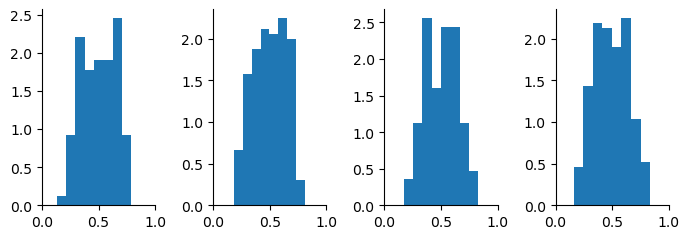

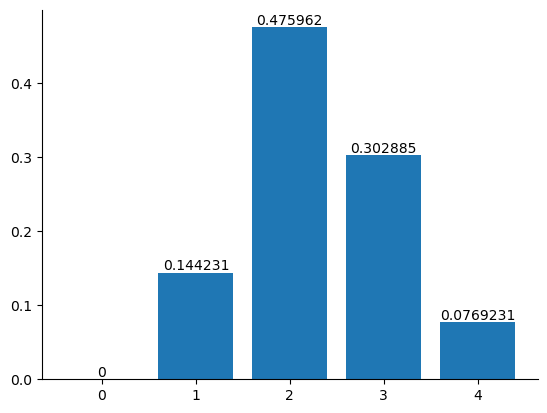

In [52]:
time_stamp = [240,270,300,330]
thresh = 5
f,axes = plt.subplots(1,len(time_stamp),figsize=(7,2.5))
ave_cluster = np.zeros(len(time_stamp))
for j in range(len(time_stamp)):
    print('################# stamp',time_stamp[j],'#################')
    gg = pop_check(cells,time_stamp[j])  ### active cells
    print(len(gg))
    #g = np.zeros([len(gg),5])  #### cluster sizes
    copy = np.zeros(len(gg))
    inheritance = np.zeros(len(gg)-1)
    
    cluster_num = np.zeros(len(gg))
    sum_cluster = 0 #np.zeros(len(gg))

    for i in range(len(gg)):
        copy[i]=gg[i].x[-1]
        if i>0:
            parent = [x for x in cells if x.index == gg[i].parent]
            inheritance[i-1] =gg[i].x[0]/ parent[0].x[-1]    
        ##### distribution of clusters of size at least "threshold" determination
        yy = gg[i].fin_clusters
        cluster_num[i] = np.sum(yy[thresh:max_size])+np.sum(yy[max_size+thresh:])
        len1 =np.count_nonzero(yy[thresh:max_size])
        len2 =np.count_nonzero(yy[max_size+thresh:])
        if len1+len2>0:
            sum_cluster += np.sum(np.multiply(yy[thresh:max_size],np.arange(thresh,max_size))+np.multiply(yy[max_size+thresh:],np.arange(thresh,max_size)))/(len1+len2)
    ave_cluster[j] = sum_cluster/len(gg)
    height = np.bincount(cluster_num.astype(int))/len(cluster_num)
    dummy=np.sum(height[4:])
    heights=np.zeros(5)
    if len(height)>4:
        height[4]=dummy
        heights = np.delete(height,np.arange(5,len(height)))    
    else:
        heights[:len(height)]=height
        #g[i,:]=heights        
        
    print('average cluster size',ave_cluster[j])
    print('population mean',np.mean(copy))
    print('population std',np.std(copy))
    print('inheritance mean',np.std(inheritance))
    axes[j].hist(inheritance,density=True,bins=8)
    axes[j].set_xlim([0,1])
plt.tight_layout()
sns.despine()

fig, ax = plt.subplots()
ax.bar([0,1,2,3,4],heights)
for bars in ax.containers:
    ax.bar_label(bars)
sns.despine()

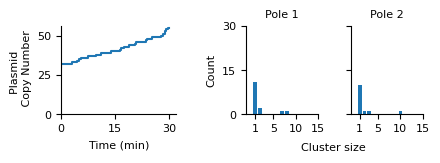

In [53]:
fontsiz = 8
idx = 30
vec = gg[idx].fin_clusters
vec[1]=vec[0]
vec[max_size+1]=vec[max_size]

gridspec = dict(hspace=0.0, width_ratios=[1.2,0.05, 0.75, 0.75])
f,axes = plt.subplots(1,4,figsize=(4.5,1.7),gridspec_kw=gridspec)


axes[0].step(gg[idx].t-gg[idx].birth,gg[idx].x)
axes[0].set_xlim([0,32])
axes[0].set_yticks([0,25,50])
axes[0].set_xticks([0,15,30])
axes[0].set_ylabel('Plasmid \n Copy Number',fontsize=fontsiz)
axes[0].set_xlabel('Time (min)',fontsize=fontsiz)
axes[0].tick_params(axis = 'both', which = 'major', labelsize = fontsiz)

axes[1].axis('off')

axes[2].bar(np.arange(1,max_size),vec[1:max_size])
axes[3].bar(np.arange(1,max_size),vec[max_size+1:])
sns.despine()
for i in range(2):
    axes[i+2].tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
    axes[i+2].set_xlim([-1,15])
    axes[i+2].set_xticks([1,5,10,15])
    #axes[i+2].set_yticks([0,5,10,15])
    axes[i+2].set_yticks([0,15,30])
    axes[i+2].set_title('Pole %d' %(i+1),fontsize=fontsiz)
axes[2].set_ylabel('Count',fontsize=fontsiz)
axes[3].set_yticklabels([])
axes[1].set_ylabel('Count',fontsize=fontsiz)
f.text(0.68,0.08,'Cluster size',fontsize=fontsiz)
plt.tight_layout(w_pad=-0.5)

#axes[0].text(-15,55,'(a)',fontsize=fontsiz+1)
#axes[2].text(-13,16.3,'(b)',fontsize=fontsiz+1)
f.savefig('stochastic_model_sims.jpg', format='jpg', dpi=500,bbox_inches="tight")

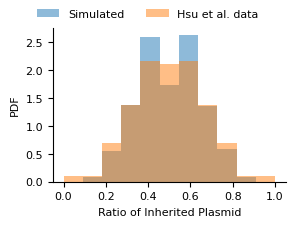

In [54]:
f,axes =plt.subplots(figsize=(3,2))
bins = np.linspace(0,1,12)
axes.hist(np.append(inheritance,1-inheritance),density=True,alpha=0.5,bins=bins,label='Simulated')
axes.hist(np.append(hsu_data,1-hsu_data),density=True,alpha=0.5,bins=bins,label='Hsu et al. data')
handles, labels = axes.get_legend_handles_labels()
axes.set_xlabel('Ratio of Inherited Plasmid',fontsize=fontsiz)
axes.set_ylabel('PDF',fontsize=fontsiz)
axes.tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
f.legend(handles, labels, loc='upper center',ncol=2,fontsize=fontsiz,frameon=False)
sns.despine()


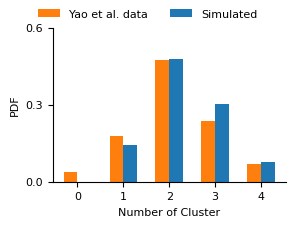

In [48]:
data_cluster = [0.03960396,0.178217822,0.475247525,0.237623762,0.069306931]
width = 0.3 
col = ['C1','C0']
fig, ax = plt.subplots(figsize=(3,2))
ax.bar(np.arange(5),data_cluster,width,label='Yao et al. data',color='C1')
ax.bar(np.arange(5)+width,heights,width,label='Simulated',color='C0')
ax.set_xticks(np.arange(5) + width / 2, np.arange(5))

#for bars in ax.containers:
#    ax.bar_label(bars, fmt='{:,.2f}',fontsize=fontsiz)
ax.tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
ax.set_ylabel('PDF',fontsize=fontsiz)
ax.set_xlabel('Number of Cluster',fontsize=fontsiz)
ax.set_yticks([0,0.3,0.6])
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center',ncol=2,fontsize=fontsiz,frameon=False)
sns.despine()

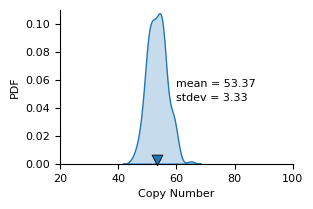

In [44]:
copy_number = np.zeros(len(gg))
for i in range(len(gg)):
    copy_number[i]=gg[i].x[-1]
f,axes = plt.subplots(figsize=(3,2))
sns.kdeplot(copy_number,shade=True)
axes.set_xlabel('Copy Number',fontsize=fontsiz)
axes.set_ylabel('PDF',fontsize=fontsiz)
axes.tick_params(axis = 'both', which = 'major', labelsize = fontsiz)
sns.scatterplot(x=[np.mean(copy_number)],y=[0.003],marker='v',s=60,ax=axes,clip_on=False,edgecolor='black',color='C0')
plt.text(60,0.045,'stdev = %1.2f' %(np.std(copy_number)),fontsize=fontsiz)
plt.text(60,0.055,'mean = %1.2f' %(np.mean(copy_number)),fontsize=fontsiz)
axes.set_xlim([20,100])
axes.set_ylim([0,0.11])
sns.despine()

In [ ]:
hsu_fin = np.append(hsu_data,1-hsu_data)
KLD = skl_efficient(hsu_fin.reshape(len(hsu_fin),1),inheritance.reshape(len(inheritance),1),k=1)

import pickle
import dill

file_name = 'cell_dec.pkl'
with open(file_name, 'wb') as file:
    pickle.dump(cells, file)

myfile = open(file_name, 'rb+')
dill.dump(cells, myfile, 2)    

# Comparisons

In [ ]:
myfile = open('cell_zero.pkl', 'rb+')
zero = dill.load(myfile)

myfile = open('cell_gamma0.pkl', 'rb+')
gamma0 = dill.load(myfile)

myfile = open('cell_complete.pkl', 'rb+')
complete = dill.load(myfile)

myfile = open('cell_dec.pkl', 'rb+')
dec = dill.load(myfile)

In [26]:
import dill
myfile = open('cell_complete.pkl', 'rb+')
cells = dill.load(myfile)